In [1]:
import pandas as pd, scipy.stats as stats
import matplotlib.pyplot as plt, seaborn as sns
from statsmodels.stats.multicomp import pairwise_tukeyhsd

url = "https://raw.githubusercontent.com/nkmwicz/data-for-students/refs/heads/main/imdb.csv"

df = pd.read_csv(url)
df.head() 

,Unnamed: 0,Rank,Title,Genre,Description,Director,Actors,Year,Runtime (Minutes),Rating,...,Drama,Music,Biography,Romance,History,Crime,Western,War,Musical,Sport
0,0,1,Guardians of the Galaxy,"Action,Adventure,Sci-Fi",A group of intergalactic criminals are forced ...,James Gunn,"Chris Pratt, Vin Diesel, Bradley Cooper, Zoe S...",2014,121,8.1,...,False,False,False,False,False,False,False,False,False,False
1,1,2,Prometheus,"Adventure,Mystery,Sci-Fi","Following clues to the origin of mankind, a te...",Ridley Scott,"Noomi Rapace, Logan Marshall-Green, Michael Fa...",2012,124,7.0,...,False,False,False,False,False,False,False,False,False,False
2,2,3,Split,"Horror,Thriller",Three girls are kidnapped by a man with a diag...,M. Night Shyamalan,"James McAvoy, Anya Taylor-Joy, Haley Lu Richar...",2016,117,7.3,...,False,False,False,False,False,False,False,False,False,False
3,3,4,Sing,"Animation,Comedy,Family","In a city of humanoid animals, a hustling thea...",Christophe Lourdelet,"Matthew McConaughey,Reese Witherspoon, Seth Ma...",2016,108,7.2,...,False,False,False,False,False,False,False,False,False,False
4,4,5,Suicide Squad,"Action,Adventure,Fantasy",A secret government agency recruits some of th...,David Ayer,"Will Smith, Jared Leto, Margot Robbie, Viola D...",2016,123,6.2,...,False,False,False,False,False,False,False,False,False,False


In [2]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 33 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Unnamed: 0          1000 non-null   int64  
 1   Rank                1000 non-null   int64  
 2   Title               1000 non-null   str    
 3   Genre               1000 non-null   str    
 4   Description         1000 non-null   str    
 5   Director            1000 non-null   str    
 6   Actors              1000 non-null   str    
 7   Year                1000 non-null   int64  
 8   Runtime (Minutes)   1000 non-null   int64  
 9   Rating              1000 non-null   float64
 10  Votes               1000 non-null   int64  
 11  Revenue (Millions)  872 non-null    float64
 12  Metascore           936 non-null    float64
 13  Action              1000 non-null   bool   
 14  Adventure           1000 non-null   bool   
 15  Sci-Fi              1000 non-null   bool   
 16  Mystery           

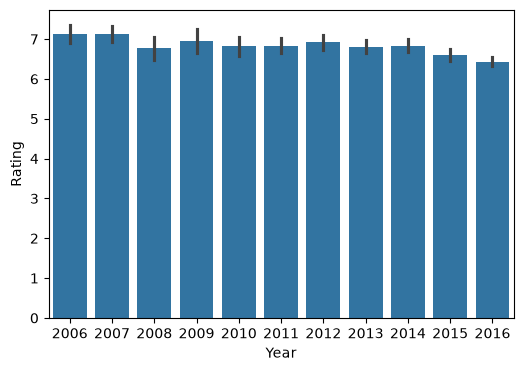

In [ ]:
plt.figure(figsize=(6,4))
bar_year = sns.barplot(data=df, x='Year', y='Rating')

In [6]:
#comparing years and ratings
yr_groups = df['Year'].unique()
yr_ratings = [df.loc[df['Year'] == yr, 'Rating']for yr in yr_groups]

f, p = stats.f_oneway(*yr_ratings)
print(f'f={f:.4f}; p={p:.4f}')
dfb = len(yr_groups) - 1
dfw = df['Rating'].count() - len(yr_groups)
alpha = 0.05
crit_f = stats.f.ppf(1-alpha, dfb, dfw)
print(f'critical f = {crit_f:.4f}')

f=6.0455; p=0.0000
critical f = 1.8403


In [7]:
tukey = pairwise_tukeyhsd(
    endog=df['Rating'],
    groups= df['Year'],
    alpha= alpha,
)

print(tukey)

Multiple Comparison of Means - Tukey HSD, FWER=0.05 
group1 group2 meandiff p-adj   lower   upper  reject
----------------------------------------------------
  2006   2007    0.009    1.0  -0.598  0.6159  False
  2006   2008  -0.3404 0.7793   -0.95  0.2692  False
  2006   2009  -0.1642 0.9987 -0.7765  0.4481  False
  2006   2010  -0.2983 0.8695  -0.889  0.2923  False
  2006   2011  -0.2869 0.8894 -0.8716  0.2978  False
  2006   2012     -0.2 0.9905 -0.7828  0.3828  False
  2006   2013  -0.3129 0.7512 -0.8594  0.2335  False
  2006   2014  -0.2872 0.8273 -0.8273  0.2528  False
  2006   2015  -0.5226 0.0481 -1.0432  -0.002   True
  2006   2016  -0.6883 0.0002  -1.169 -0.2076   True
  2007   2008  -0.3493 0.6904 -0.9302  0.2315  False
  2007   2009  -0.1732 0.9971 -0.7569  0.4106  False
  2007   2010  -0.3073 0.7992 -0.8683  0.2537  False
  2007   2011  -0.2959 0.8247 -0.8506  0.2588  False
  2007   2012   -0.209 0.9803 -0.7617  0.3437  False
  2007   2013  -0.3219 0.6353 -0.8361  0.1923 

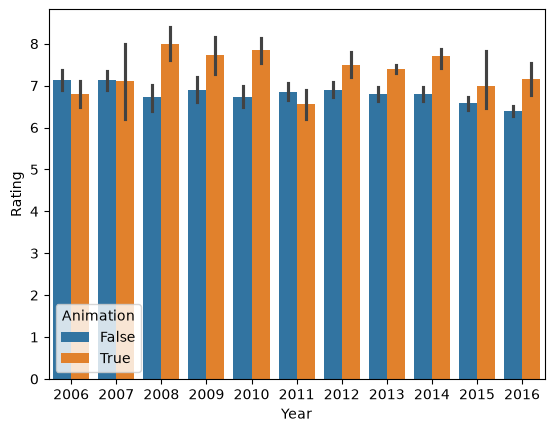

In [9]:
bar_animation_year = sns.barplot(data=df, x='Year', y='Rating', hue="Animation")

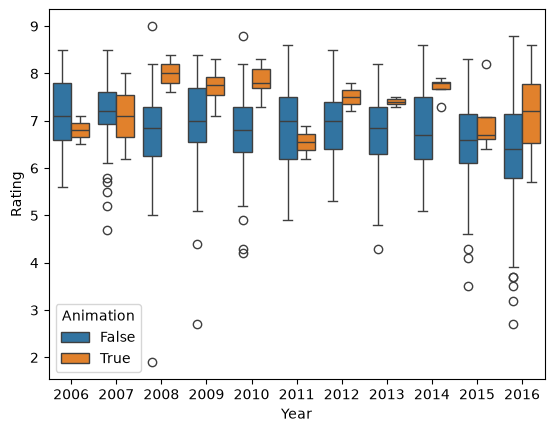

In [10]:
bar_animation_year = sns.boxplot(data=df, x='Year', y='Rating', hue="Animation")

In [13]:
g_options = [
    ["Action", "Adventure", "Sci-Fi"],
    ["Drama"],
    ["Comedy", "Romance"],
    ["Animation", "Adventure", "Comedy"],
]

df['Genre_list'] = df['Genre'].str.split(",")
df["Genre_list"]

0       [Action, Adventure, Sci-Fi]
1      [Adventure, Mystery, Sci-Fi]
2                [Horror, Thriller]
3       [Animation, Comedy, Family]
4      [Action, Adventure, Fantasy]
                   ...             
995         [Crime, Drama, Mystery]
996                        [Horror]
997         [Drama, Music, Romance]
998             [Adventure, Comedy]
999       [Comedy, Family, Fantasy]
Name: Genre_list, Length: 1000, dtype: object

In [16]:
groups_list = [
    df.loc[df["Genre_list"].apply(lambda x: bool(set(x) & set(opt))), "Rating"] #lambda is anonymous function
    for opt in g_options 
]
groups_mean = [group.mean() for group in groups_list]
groups_mean
#set(g_options[0]) & set(g_options[-1]) 
#this notation tells us where lines intersect/ commonalities between lists

[np.float64(6.712387387387388),
 np.float64(6.953801169590643),
 np.float64(6.7037249283667615),
 np.float64(6.690683229813665)]

In [17]:
g_names = ["/".join(opt)for opt in g_options]
g_names

['Action/Adventure/Sci-Fi',
 'Drama',
 'Comedy/Romance',
 'Animation/Adventure/Comedy']

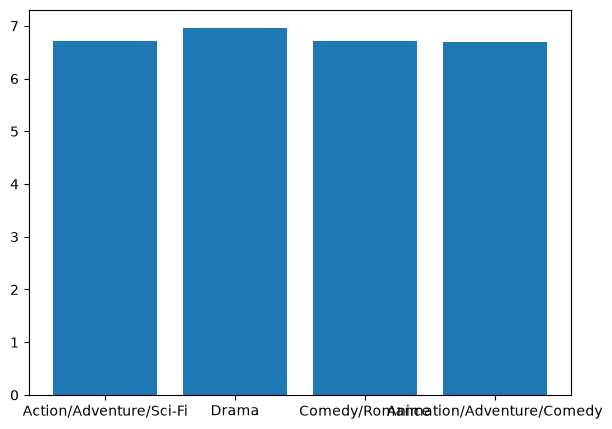

In [21]:
plt.figure(figsize=(7,5))
plt.bar(x= g_names, height= groups_mean)
plt.show()

In [22]:
f, p = stats.f_oneway(*groups_list)
dfb = len(g_options) - 1
dfw = sum([len(item) for item in groups_list]) - len(g_options)
crit_f = stats.f.ppf(1-alpha, dfb, dfw)
print(f'f={f:.4f}, p={p:.4f}, critical ={crit_f:.4f}')

f=9.7919, p=0.0000, critical =2.6099


In [23]:
stats_tukey = stats.tukey_hsd(*groups_list)
print(stats_tukey)
print(g_names)

Pairwise Group Comparisons (95.0% Confidence Interval)
Comparison  Statistic  p-value  Lower CI  Upper CI
 (0 - 1)     -0.241     0.000    -0.390    -0.093
 (0 - 2)      0.009     0.999    -0.155     0.173
 (0 - 3)      0.022     0.983    -0.129     0.172
 (1 - 0)      0.241     0.000     0.093     0.390
 (1 - 2)      0.250     0.000     0.091     0.409
 (1 - 3)      0.263     0.000     0.118     0.408
 (2 - 0)     -0.009     0.999    -0.173     0.155
 (2 - 1)     -0.250     0.000    -0.409    -0.091
 (2 - 3)      0.013     0.997    -0.148     0.174
 (3 - 0)     -0.022     0.983    -0.172     0.129
 (3 - 1)     -0.263     0.000    -0.408    -0.118
 (3 - 2)     -0.013     0.997    -0.174     0.148

['Action/Adventure/Sci-Fi', 'Drama', 'Comedy/Romance', 'Animation/Adventure/Comedy']
